# 07 Task 7: network expansion
**Problem.** A new node $q$ at given coordinates must join the network through one new pipe to the nearest existing node that is not a source:
$$t^*=\arg\min_{v\in V\setminus S}\lVert p_v-q\rVert_2 .$$
Then the graph representations must be updated with the new vertex and pipe.

**Input:** the instance and the `[NEW]` records `x y capacity`. **Output:** the selected connection and its length, the updated network, and the cost of the search and of the update.

**Conventions.** The slides give the new node by coordinates only (their FOS example adds node 38 next to node 17). The files list two or three new points per instance; they are inserted one at a time in file order, each receiving the next free id (as node 38 in the slides), and each is linked to the nearest non-source node of the network as it stands, so an earlier new node is itself a candidate. The third value of a record is taken as the capacity of the new pipe, and the pipe length is the Euclidean distance (task 2). NYT's second record (6478, 3050) is rejected as an outlier in `00_data` and not inserted.

**Techniques.** *Brute force:* compare $q$ with all $n$ candidates, $O(n)$ per query. *Divide and conquer:* a 2-d tree splits the candidates at the median of alternating coordinates; a query descends towards $q$ and only visits the other side of a split when the splitting line is closer than the best distance found so far (branch and prune). Expected query cost is $O(\log n)$ for well-spread points, at the price of an $O(n\log n)$ build (our build re-sorts at each level, $O(n\log^2 n)$).

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
import math
import random
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree
import water
from water import graph, plot, spatial, tasks

plot.setup()
nets = water.load_all()

In [2]:
print(inspect.getsource(spatial.KDTree.nearest))
print(inspect.getsource(tasks.expand_network))

    def nearest(self, q):
        """branch and prune: visit the near child first, the far child only if the
        splitting line is closer than the best distance so far."""
        best = [None, math.inf, 0]

        def visit(node):
            if node is None:
                return
            best[2] += 1
            d = math.dist(node[1], q)
            if d < best[1] or (d == best[1] and node[0] < best[0]):
                best[0], best[1] = node[0], d
            diff = q[node[2]] - node[1][node[2]]
            near, far = (node[3], node[4]) if diff < 0 else (node[4], node[3])
            visit(near)
            if abs(diff) <= best[1]:
                visit(far)

        visit(self.root)
        return tuple(best)

def expand_network(net):
    """t7: insert each new node in file order, linked to the nearest non-source node of the
    network as it stands (earlier new nodes are candidates). returns the grown network and
    one record per insertion."""
    grown = copy.deepco

## Correctness of the search
On every instance the 2-d tree is compared with brute force and with `scipy.spatial.cKDTree` on 2,000 random query points inside the network's bounding box (fixed seed) and on every inserted node.

In [3]:
rng = random.Random(2038)
for name, net in nets.items():
    cand = {u: xy for u, xy in net.coords.items() if u not in net.sources}
    tree, ref = spatial.KDTree(cand), cKDTree(np.array(list(cand.values())))
    keys = list(cand)
    x0, x1, y0, y1 = net.bbox()
    visited = []
    for _ in range(2000):
        q = (rng.uniform(x0, x1), rng.uniform(y0, y1))
        u, d, n = tree.nearest(q)
        b, db, _ = spatial.brute_nearest(cand, q)
        dr, i = ref.query(q)
        assert abs(d - db) < 1e-9 and abs(d - dr) < 1e-9
        visited.append(n)
    print(f'{name}: {len(cand)} candidates, tree depth {tree.depth()} | 2,000 random queries agree with brute force '
          f'and scipy | distance evaluations: tree mean {np.mean(visited):.1f} (max {max(visited)}), brute force {len(cand)}')

NYT: 18 candidates, tree depth 5 | 2,000 random queries agree with brute force and scipy | distance evaluations: tree mean 6.7 (max 17), brute force 18
HAN: 30 candidates, tree depth 5 | 2,000 random queries agree with brute force and scipy | distance evaluations: tree mean 8.6 (max 21), brute force 30
FOS: 35 candidates, tree depth 6 | 2,000 random queries agree with brute force and scipy | distance evaluations: tree mean 7.8 (max 19), brute force 35
PES: 69 candidates, tree depth 7 | 2,000 random queries agree with brute force and scipy | distance evaluations: tree mean 11.0 (max 26), brute force 69


## Insertions

In [4]:
grown_nets, rows = {}, []
for name, net in nets.items():
    grown, added = tasks.expand_network(net)
    cand = {u: xy for u, xy in net.coords.items() if u not in net.sources}
    for a in added:
        b, db, nb = spatial.brute_nearest(cand, a['xy'])
        assert b == a['target'] and abs(db - a['dist']) < 1e-9
        cand[a['id']] = a['xy']
        print(f'{name}: node {a["id"]} at ({a["xy"][0]:g}, {a["xy"][1]:g}) -> node {a["target"]}, new pipe length '
              f'{a["dist"]:.2f}, capacity {a["capacity"]:g} | evaluations: tree {a["visited"]}, brute force {nb}')
        rows.append([name, a['id'], f'({a["xy"][0]:g}, {a["xy"][1]:g})', a['target'], a['dist'], a['capacity'],
                     a['visited'], nb])
    grown_nets[name] = (grown, added)

plot.table('expansion', rows,
           ['Inst.', 'New id', 'Coordinates', 'Linked to', 'Length', 'Capacity', 'Tree eval.', 'Brute eval.'],
           ['{}', '{}', '{}', '{}', '{:.1f}', '{:g}', '{}', '{}'])

NYT: node 21 at (930, 1779) -> node 13, new pipe length 150.01, capacity 120 | evaluations: tree 4, brute force 18
NYT: node 22 at (1269, 1069) -> node 20, new pipe length 217.04, capacity 170 | evaluations: tree 4, brute force 19
HAN: node 33 at (8457, 5177) -> node 9, new pipe length 353.00, capacity 18 | evaluations: tree 5, brute force 30
HAN: node 34 at (6478, 3050) -> node 5, new pipe length 607.68, capacity 20 | evaluations: tree 9, brute force 31
HAN: node 35 at (595, 5929) -> node 32, new pipe length 793.53, capacity 17 | evaluations: tree 6, brute force 32
FOS: node 38 at (7071, 9055) -> node 17, new pipe length 617.15, capacity 50 | evaluations: tree 5, brute force 35
FOS: node 39 at (1957, 9160) -> node 5, new pipe length 809.13, capacity 45 | evaluations: tree 7, brute force 36
PES: node 90 at (657029, 963601) -> node 3, new pipe length 363.68, capacity 120 | evaluations: tree 9, brute force 69
PES: node 91 at (662127, 961448) -> node 25, new pipe length 645.74, capacity 1

No new node lands closest to another new node, so the file order does not change any connection here. Every target is a non-source junction; for example the FOS point (7071, 9055) links to node 17, the connection drawn in the challenge slides for node 38.

## Updating the representations
Adjacency list: add one key and append one entry at each endpoint, $O(1)$ amortised. Adjacency matrix: a NumPy array cannot grow in place, so a $(V+1)\times(V+1)$ array is allocated and the old $V^2$ cells copied, $O(V^2)$ per insertion. Both updated structures are checked against structures rebuilt from scratch on the expanded network.

In [5]:
def add_to_list(adj, nid, target, w):
    adj[nid] = [(target, w)]
    adj[target].append((nid, w))

def add_to_matrix(M, ids, index, nid, target, w):
    n = len(M)
    out = np.zeros((n + 1, n + 1))
    out[:n, :n] = M
    out[n, index[target]] = out[index[target], n] = w
    return out, ids + [nid], {**index, nid: n}

for name, net in nets.items():
    grown, added = grown_nets[name]
    adj = graph.adjacency_list(net)
    M, ids, index = graph.adjacency_matrix(net)
    copied = 0
    for a in added:
        add_to_list(adj, a['id'], a['target'], a['dist'])
        copied += len(M) ** 2
        M, ids, index = add_to_matrix(M, ids, index, a['id'], a['target'], a['dist'])
    ref_adj = graph.adjacency_list(grown)
    ref_M, ref_ids, _ = graph.adjacency_matrix(grown)
    assert {u: sorted(v) for u, v in adj.items()} == {u: sorted(v) for u, v in ref_adj.items()}
    assert ids == ref_ids and np.allclose(M, ref_M)
    print(f'{name}: {len(added)} insertions | list: {3 * len(added)} entries written | '
          f'matrix: {copied:,} cells copied | updated structures equal rebuilt ones')

NYT: 2 insertions | list: 6 entries written | matrix: 841 cells copied | updated structures equal rebuilt ones
HAN: 3 insertions | list: 9 entries written | matrix: 3,269 cells copied | updated structures equal rebuilt ones
FOS: 2 insertions | list: 6 entries written | matrix: 2,813 cells copied | updated structures equal rebuilt ones
PES: 2 insertions | list: 6 entries written | matrix: 10,225 cells copied | updated structures equal rebuilt ones


## Figure

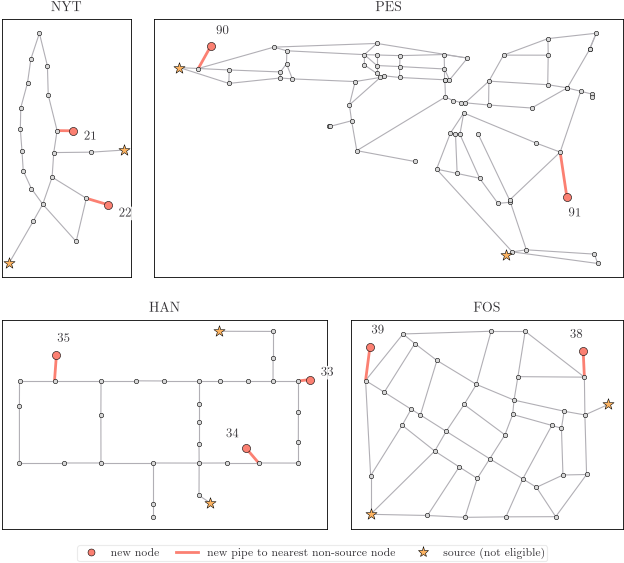

In [6]:
fig, axes = plot.instance_axes({k: v[0] for k, v in grown_nets.items()})
for name, ax in axes.items():
    net = nets[name]
    grown, added = grown_nets[name]
    plot.pipes(ax, net)
    plot.nodes(ax, net, [u for u in net.coords if u not in net.sources], s=10)
    plot.sources(ax, net)
    plot.pipes(ax, grown, [(a['id'], a['target'], 0) for a in added], color=plot.HIGHLIGHT, lw=2.0)
    plot.nodes(ax, grown, [a['id'] for a in added], color=plot.HIGHLIGHT, s=34, zorder=6)
    for a in added:
        # label on the far side of the new node, away from its pipe
        dx, dy = (a['xy'][0] - grown.coords[a['target']][0], a['xy'][1] - grown.coords[a['target']][1])
        n = math.hypot(dx, dy)
        ax.annotate(str(a['id']), a['xy'], xytext=(8 * dx / n, 8 * dy / n), textcoords='offset points',
                    ha='left' if dx >= 0 else 'right', va='bottom' if dy >= 0 else 'top', fontsize=9, zorder=7,
                    bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.85))
    plot.frame(ax, name)
h = [plt.Line2D([], [], ls='', marker='o', mfc=plot.HIGHLIGHT, mec='k', mew=0.4, ms=5, label='new node'),
     plt.Line2D([], [], color=plot.HIGHLIGHT, lw=2.0, label='new pipe to nearest non-source node'),
     plt.Line2D([], [], ls='', marker='*', mfc=plot.SOURCE, mec='k', mew=0.4, ms=8, label='source (not eligible)')]
fig.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3)
plot.save(fig, 'expansion')
plt.show()

## Complexity
| | build | query / update |
|---|---|---|
| brute force | none | $O(n)$ |
| 2-d tree | $O(n\log^2 n)$ here ($O(n\log n)$ with linear-time median) | expected $O(\log n)$, worst $O(n)$; insert $O(\text{depth})$ |
| adjacency list update | | $O(1)$ amortised |
| adjacency matrix update | | $O(V^2)$ copy |

## Interpretation
The tree evaluates on average 37% (NYT, 18 candidates) down to 16% (PES, 69 candidates) of the distances brute force does, and the fraction falls as the network grows, but its build costs more than a handful of brute-force queries, so for a utility adding a few nodes at a time brute force is perfectly adequate; the tree pays off when many connection requests are served against the same network (timings in `08_performance`). For the graph update the list is clearly the right representation: each insertion touches three entries, whereas the matrix copies the whole table.